In [ ]:
from google.colab import drive
import os

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Sesuaikan lokasi folder simuteh-2330511031 kamu di Drive
# (Kalau foldermu ada di dalam folder lain, misal MyDrive/Kuliah/simuteh-2330511031, ubah baris di bawah ya)
BASE_DIR = "/content/drive/MyDrive/simuteh-2330511031"

# Pastikan subfolder ada
for sub in ["notebook", "src", "hasil"]:
    os.makedirs(os.path.join(BASE_DIR, sub), exist_ok=True)

# 3. Otomatis membuat src/utils_tepi.py sesuai Lampiran A
kode_utils_tepi = '''"""utils_tepi.py: fungsi bantu evaluasi deteksi tepi dan morfologi (P5-P6 SIMUTEH)."""
import cv2
import numpy as np


def tepi_acuan(mask):
    """Tepi acuan selebar 1 piksel dari sebuah mask biner (255 = objek)."""
    m = (mask > 0).astype(np.uint8)
    return ((m - cv2.erode(m, np.ones((3, 3), np.uint8))) > 0).astype(np.uint8) * 255


def skor_tepi(prediksi, acuan, toleransi=2):
    """Presisi, recall, dan F1 tepi dengan toleransi jarak (piksel).
    Presisi: porsi piksel tepi prediksi yang berjarak <= toleransi dari tepi acuan.
    Recall : porsi piksel tepi acuan yang berjarak <= toleransi dari tepi prediksi."""
    p = prediksi > 0
    a = acuan > 0
    if p.sum() == 0 or a.sum() == 0:
        return 0.0, 0.0, 0.0
    jarak_ke_a = cv2.distanceTransform((~a).astype(np.uint8), cv2.DIST_L2, 3)
    jarak_ke_p = cv2.distanceTransform((~p).astype(np.uint8), cv2.DIST_L2, 3)
    presisi = float((jarak_ke_a[p] <= toleransi).mean())
    recall = float((jarak_ke_p[a] <= toleransi).mean())
    f1 = 0.0 if presisi + recall == 0 else 2 * presisi * recall / (presisi + recall)
    return round(presisi, 3), round(recall, 3), round(f1, 3)


def iou(a, b):
    """Intersection over Union dua mask biner."""
    a, b = a > 0, b > 0
    gabungan = (a | b).sum()
    return 1.0 if gabungan == 0 else float((a & b).sum() / gabungan)


def mask_daun_awal(img_bgr):
    """Mask daun sementara: ambang Otsu pada kanal saturasi (dibahas tuntas di P7)."""
    s = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)[:, :, 1]
    _, m = cv2.threshold(s, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return m


def bercak_awal(img_bgr, mask_daun, kanal=2, k=4.0):
    """Citra biner bercak sementara: piksel daun pada kanal terpilih yang lebih
    terang dari median daun + k x MAD (simpangan median absolut, dikali 1,4826).
    Median dan MAD dipakai karena tidak ikut terseret oleh bercak yang luas.
    Hasilnya sengaja masih kasar: memuat titik derau, potongan tulang daun,
    dan tepi daun yang harus dibersihkan dengan operasi morfologi (P6)."""
    c = img_bgr[:, :, kanal].astype(np.float32)
    m = mask_daun > 0
    med = np.median(c[m])
    mad = 1.4826 * np.median(np.abs(c[m] - med))
    return (((c > med + k * mad) & m) * 255).astype(np.uint8)
'''

with open(os.path.join(BASE_DIR, "src/utils_tepi.py"), "w") as f:
    f.write(kode_utils_tepi)

# 4. Pindah working directory ke folder notebook/
os.chdir(os.path.join(BASE_DIR, "notebook"))
print("Working directory saat ini:", os.getcwd())
print("Isi folder src/:", os.listdir("../src"))
print("Isi folder hasil/:", os.listdir("../hasil"))

Mounted at /content/drive
Working directory saat ini: /content/drive/MyDrive/simuteh-2330511031/notebook
Isi folder src/: ['buat_dataset_sintetis.py', '__pycache__', 'praproses.py', 'utils_cv.py', 'utils_tepi.py']
Isi folder hasil/: ['b4_tabel_penapis.csv', 'param_praproses.json', 'b3_histogram_5kondisi.png', 'b2_kb_kanal_berat.csv', 'b1_5_kondisi.png', 'b1_bgr_rgb.png']


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


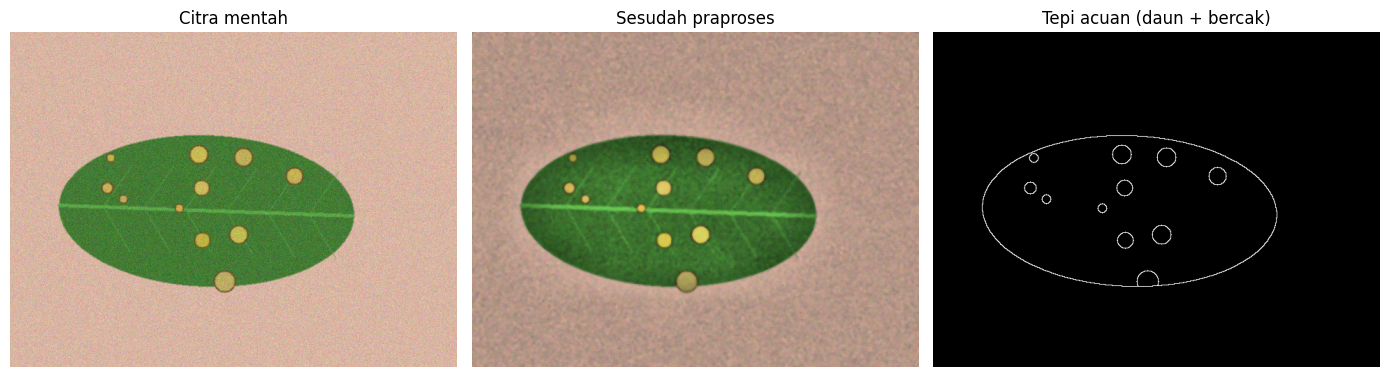

In [ ]:
import sys, json
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
PARAM = json.load(open("../hasil/param_praproses.json"))   # hasil Evaluasi P1-P4
label = pd.read_csv("../data/sintetis/label.csv")

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)
acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
tampil([img, pra, acuan], ["Citra mentah", "Sesudah praproses", "Tepi acuan (daun + bercak)"])

selisih maks gx manual vs cv2.Sobel: 0.0
magnitudo maks: 552.4


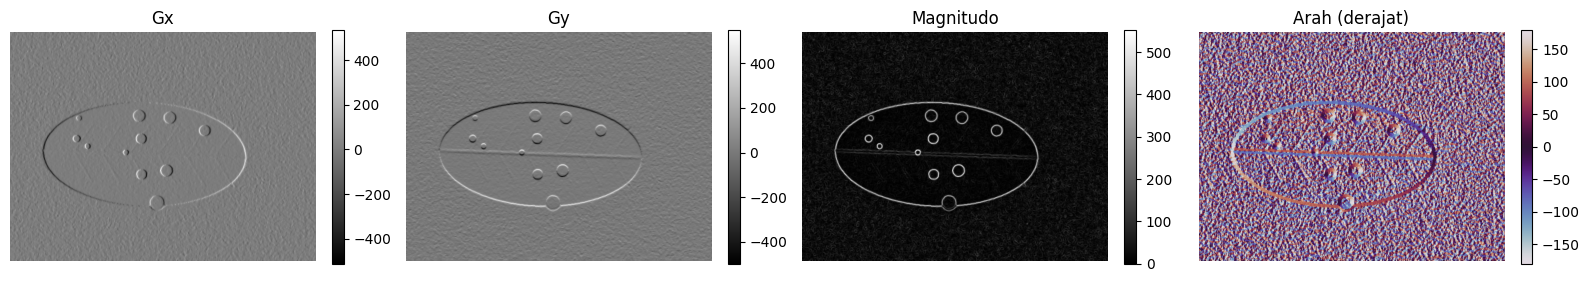

In [ ]:
g = pra[:, :, 2].astype(np.float32)          # kanal R hasil praproses
kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
ky = kx.T
gx = cv2.filter2D(g, cv2.CV_32F, kx)         # turunan arah x (tepi vertikal)
gy = cv2.filter2D(g, cv2.CV_32F, ky)         # turunan arah y (tepi horizontal)
mag = np.sqrt(gx ** 2 + gy ** 2)
arah = np.degrees(np.arctan2(gy, gx))

# bandingkan dengan fungsi pustaka
gx_cv = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
print("selisih maks gx manual vs cv2.Sobel:", np.abs(gx - gx_cv).max())
print("magnitudo maks:", mag.max().round(1))

plt.figure(figsize=(16, 3.6))
for i, (c, jd) in enumerate([(gx, "Gx"), (gy, "Gy"), (mag, "Magnitudo"), (arah, "Arah (derajat)")]):
    plt.subplot(1, 4, i + 1); plt.imshow(c, cmap="twilight" if i == 3 else "gray")
    plt.title(jd); plt.axis("off"); plt.colorbar(fraction=0.035)
plt.tight_layout()
plt.show()

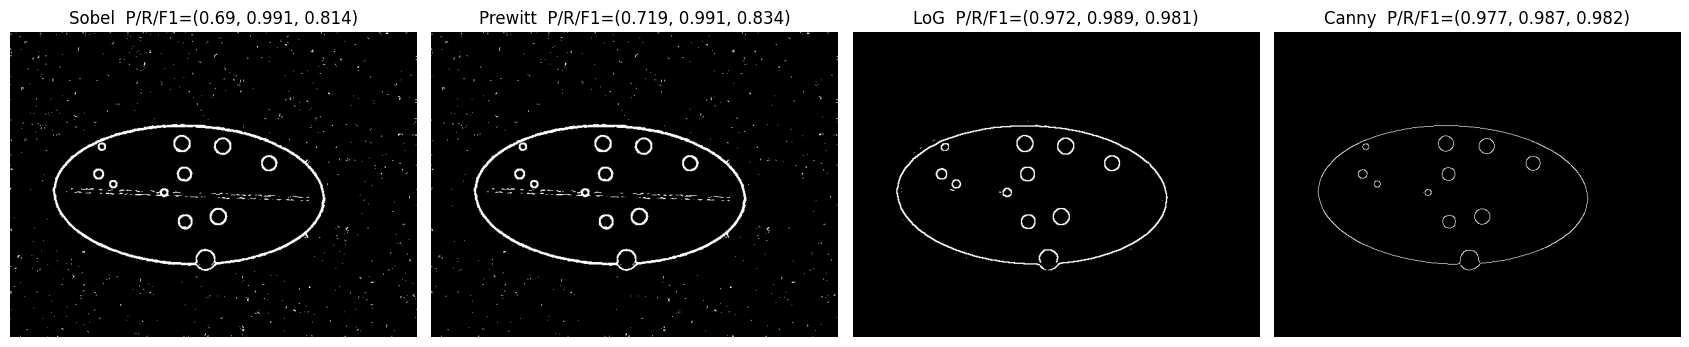

In [ ]:
def tepi_sobel(g, T=100):
    g = g.astype(np.float32)
    m = np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
    return ((m > T) * 255).astype(np.uint8)

def tepi_prewitt(g, T=75):
    kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
    g = g.astype(np.float32)
    m = np.hypot(cv2.filter2D(g, -1, kx), cv2.filter2D(g, -1, kx.T))
    return ((m > T) * 255).astype(np.uint8)

def tepi_log(g, sigma=3.0, frac=0.2):
    """Laplacian of Gaussian: tepi = perlintasan nol yang cukup kuat."""
    L = cv2.Laplacian(cv2.GaussianBlur(g.astype(np.float32), (0, 0), sigma), cv2.CV_32F)
    mn, mx = cv2.erode(L, np.ones((3, 3))), cv2.dilate(L, np.ones((3, 3)))
    return (((mn < 0) & (mx > 0) & (mx - mn > frac * np.abs(L).max())) * 255).astype(np.uint8)

def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

metode = {"Sobel": tepi_sobel, "Prewitt": tepi_prewitt, "LoG": tepi_log, "Canny": tepi_canny}
g = pra[:, :, 2]
hasil = {nm: f(g) for nm, f in metode.items()}
tampil(list(hasil.values()), [f"{nm}  P/R/F1={skor_tepi(e, acuan)}" for nm, e in hasil.items()],
       ukuran=(17, 3.6))

In [ ]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    for sumber, im in [("mentah", img), ("praproses", praproses(img, PARAM))]:
        for kanal, g in [("Gray", cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)), ("R", im[:, :, 2])]:
            for nm, f in metode.items():
                p, r, f1 = skor_tepi(f(g), ac)
                baris.append([d.kondisi_cahaya, sumber, kanal, nm, p, r, f1])

tabel_tepi = pd.DataFrame(baris, columns=["kondisi", "sumber", "kanal", "metode", "P", "R", "F1"])
ringkas = tabel_tepi.groupby(["sumber", "kanal", "metode"])[["P", "R", "F1"]].mean().round(3)
print("=== RINGKASAN P, R, F1 ===")
print(ringkas)
tabel_tepi.to_csv("../hasil/p5_tabel_tepi.csv", index=False)

# Cetak langsung sesuai format Tabel 6 di modul
tabel_6 = tabel_tepi.pivot_table(
    index="metode", columns=["sumber", "kanal"], values="F1", aggfunc="mean"
).loc[["Sobel", "Prewitt", "LoG", "Canny"], [("mentah", "Gray"), ("mentah", "R"), ("praproses", "Gray"), ("praproses", "R")]].round(3)
print("\n=== FORMAT TABEL 6 (RERATA F1) ===")
print(tabel_6)

=== RINGKASAN P, R, F1 ===
                             P      R     F1
sumber    kanal metode                      
mentah    Gray  Canny    0.735  0.754  0.741
                LoG      0.656  0.998  0.786
                Prewitt  0.815  0.959  0.870
                Sobel    0.788  0.966  0.856
          R     Canny    0.988  0.982  0.984
                LoG      0.917  0.997  0.951
                Prewitt  0.567  0.997  0.686
                Sobel    0.494  0.997  0.618
praproses Gray  Canny    0.712  0.948  0.805
                LoG      0.609  0.997  0.752
                Prewitt  0.768  0.994  0.863
                Sobel    0.766  0.994  0.862
          R     Canny    0.975  0.986  0.981
                LoG      0.912  0.997  0.949
                Prewitt  0.873  0.996  0.928
                Sobel    0.867  0.996  0.924

=== FORMAT TABEL 6 (RERATA F1) ===
sumber  mentah        praproses       
kanal     Gray      R      Gray      R
metode                                
Sobel    0

=== F1 PER KONDISI CAHAYA (KANAL R, PRAPROSES) ===
metode          Sobel  Prewitt    LoG  Canny
kondisi                                     
bayangan        0.946    0.948  0.970  0.975
gelap           0.882    0.890  0.978  0.980
kontras_rendah  0.974    0.974  0.879  0.978
normal          0.888    0.894  0.972  0.988
terang          0.932    0.936  0.943  0.983


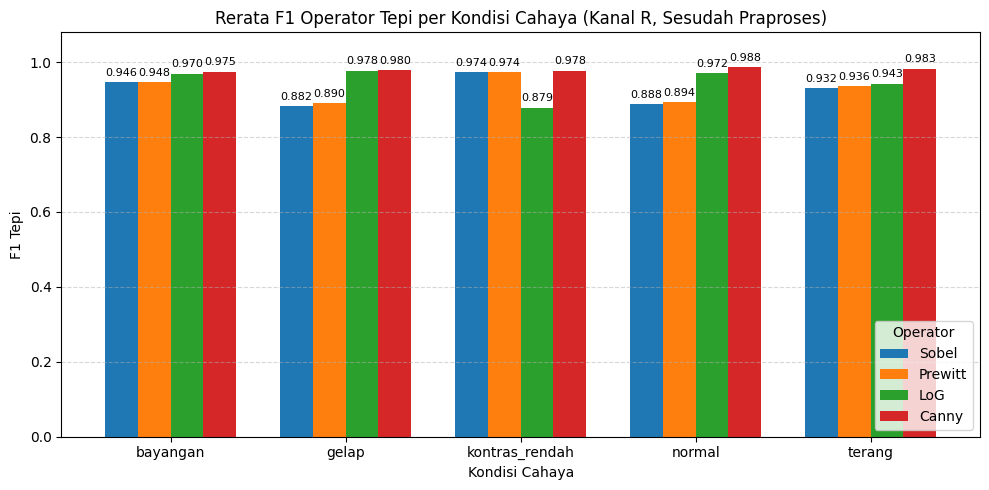

In [ ]:
# Langkah 1.5: Grafik batang F1 per kondisi cahaya untuk keempat operator pada kanal R sesudah praproses
df_r_pra = tabel_tepi[(tabel_tepi["sumber"] == "praproses") & (tabel_tepi["kanal"] == "R")]
f1_kondisi = df_r_pra.pivot_table(
    index="kondisi", columns="metode", values="F1", aggfunc="mean"
)[["Sobel", "Prewitt", "LoG", "Canny"]].round(3)

print("=== F1 PER KONDISI CAHAYA (KANAL R, PRAPROSES) ===")
print(f1_kondisi)

ax = f1_kondisi.plot(kind="bar", figsize=(10, 5), rot=0, width=0.75)
ax.set_title("Rerata F1 Operator Tepi per Kondisi Cahaya (Kanal R, Sesudah Praproses)")
ax.set_xlabel("Kondisi Cahaya")
ax.set_ylabel("F1 Tepi")
ax.set_ylim(0, 1.08)
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.legend(title="Operator", loc="lower right")

for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", padding=3, fontsize=8)

plt.tight_layout()
plt.savefig("../hasil/p5_f1_kondisi.png", dpi=150)
plt.show()

In [ ]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    g = praproses(img, PARAM)[:, :, 2]
    ad, ab = tepi_acuan(md), tepi_acuan(mb)
    ac = cv2.bitwise_or(ad, ab)
    for sigma in [0, 1.0, 2.0]:
        for lo, hi in [(30, 90), (50, 150), (100, 200)]:
            e = tepi_canny(g, lo, hi, sigma)
            p, r, f1 = skor_tepi(e, ac)
            r_bercak = skor_tepi(e, ab)[1]      # recall khusus tepi bercak
            baris.append([d.kelas, sigma, f"{lo}/{hi}", p, r, f1, r_bercak])

canny = pd.DataFrame(baris, columns=["kelas", "sigma", "ambang", "P", "R", "F1", "R_bercak"])

# Gabungkan langsung ke format Tabel 7
r_umum = canny.groupby(["sigma", "ambang"])[["P", "R", "F1", "R_bercak"]].mean().round(3)
r_kelas = canny.pivot_table(index=["sigma", "ambang"], columns="kelas", values="R_bercak").round(3)
tabel_7 = r_umum[["P", "R", "F1"]].join(r_kelas[["berat", "ringan"]]).rename(
    columns={"berat": "R_bercak (berat)", "ringan": "R_bercak (ringan)"}
)
# Urutkan sesuai urutan baris di Tabel 7 modul
urutan_idx = [(s, a) for s in [0.0, 1.0, 2.0] for a in ["30/90", "50/150", "100/200"]]
tabel_7 = tabel_7.loc[urutan_idx]
print("=== FORMAT TABEL 7 ===")
print(tabel_7)
tabel_7.to_csv("../hasil/p5_tabel7_canny.csv")

=== FORMAT TABEL 7 ===
                   P      R     F1  R_bercak (berat)  R_bercak (ringan)
sigma ambang                                                           
0.0   30/90    0.139  0.994  0.223             0.981              0.938
      50/150   0.705  0.992  0.796             0.976              0.933
      100/200  0.970  0.991  0.980             0.970              0.931
1.0   30/90    0.696  0.992  0.801             0.976              0.917
      50/150   0.977  0.991  0.984             0.970              0.914
      100/200  0.989  0.987  0.988             0.957              0.891
2.0   30/90    0.975  0.986  0.981             0.952              0.900
      50/150   0.963  0.952  0.957             0.918              0.748
      100/200  0.795  0.781  0.788             0.740              0.560


In [ ]:
def canny_otomatis(g, s=0.33):
    """Ambang dari median intensitas: bawah = (1-s) x median, atas = (1+s) x median."""
    v = np.median(g)
    return cv2.Canny(g, int(max(0, (1 - s) * v)), int(min(255, (1 + s) * v)))

baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        baris.append([d.kondisi_cahaya, kanal, "otomatis", skor_tepi(canny_otomatis(g), ac)[2], np.median(g)])
        baris.append([d.kondisi_cahaya, kanal, "tetap 30/90", skor_tepi(tepi_canny(g), ac)[2], np.median(g)])

auto = pd.DataFrame(baris, columns=["kondisi", "kanal", "ambang", "F1", "median"])
print("=== F1 AMBANG OTOMATIS MEDIAN VS TETAP 30/90 ===")
print(auto.pivot_table(index=["kanal", "ambang"], columns="kondisi", values="F1").round(3))
print("\n=== RERATA MEDIAN INTENSITAS PER KONDISI ===")
print(auto.groupby(["kanal", "kondisi"])["median"].mean().round(1))

# Tambahan bantu hitung gradien tepi daun pada kontras_rendah (untuk menjawab P2.3 secara presisi)
grad_kr = []
for _, d in label[(label.kelas != "sehat") & (label.kondisi_cahaya == "kontras_rendah")].iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    td = tepi_acuan(md) > 0
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        gf = cv2.GaussianBlur(g.astype(np.float32), (0, 0), 2.0)
        mag = np.hypot(cv2.Sobel(gf, cv2.CV_32F, 1, 0), cv2.Sobel(gf, cv2.CV_32F, 0, 1))
        mag_raw = np.hypot(cv2.Sobel(g.astype(np.float32), cv2.CV_32F, 1, 0), cv2.Sobel(g.astype(np.float32), cv2.CV_32F, 0, 1))
        grad_kr.append([kanal, np.median(mag_raw[td]), np.median(mag[td]), np.percentile(mag[td], 90)])
print("\n=== MAGNITUDO GRADIEN DI TEPI DAUN PADA KONTRAS RENDAH (UNTUK P2.3) ===")
print(pd.DataFrame(grad_kr, columns=["kanal", "med_grad_sigma0", "med_grad_sigma2", "p90_grad_sigma2"]).groupby("kanal").mean().round(1))

=== F1 AMBANG OTOMATIS MEDIAN VS TETAP 30/90 ===
kondisi            bayangan  gelap  kontras_rendah  normal  terang
kanal ambang                                                      
Gray  otomatis        0.782  0.778           0.968   0.857   0.984
      tetap 30/90     0.759  0.773           0.914   0.758   0.823
R     otomatis        0.971  0.975           0.984   0.986   0.989
      tetap 30/90     0.975  0.980           0.978   0.988   0.983

=== RERATA MEDIAN INTENSITAS PER KONDISI ===
kanal  kondisi       
Gray   bayangan          116.9
       gelap             136.9
       kontras_rendah    150.1
       normal            166.6
       terang            192.5
R      bayangan          124.1
       gelap             150.4
       kontras_rendah    152.5
       normal            181.6
       terang            197.6
Name: median, dtype: float64

=== MAGNITUDO GRADIEN DI TEPI DAUN PADA KONTRAS RENDAH (UNTUK P2.3) ===
       med_grad_sigma0  med_grad_sigma2  p90_grad_sigma2
kanal       

In [ ]:
def canny_persentil(g, q, rasio=0.4, sigma=2.0):
    """Perbaikan ambang otomatis Canny berbasis persentil ke-q magnitudo Sobel."""
    # (1) Haluskan citra dengan Gaussian
    g_halus = cv2.GaussianBlur(g, (0, 0), sigma) if sigma > 0 else g.copy()
    # (2) Hitung magnitudo Sobel
    gx = cv2.Sobel(g_halus.astype(np.float32), cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(g_halus.astype(np.float32), cv2.CV_32F, 0, 1, ksize=3)
    mag = np.hypot(gx, gy)
    # (3) Persentil ke-q magnitudo sebagai ambang atas, rasio x atas sebagai ambang bawah
    hi = float(np.percentile(mag, q))
    lo = float(rasio * hi)
    # (4) Panggil cv2.Canny
    return cv2.Canny(g_halus, int(round(lo)), int(round(hi)))

baris_p = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        # Bandingkan dengan Kode 2.2
        baris_p.append([d.kondisi_cahaya, kanal, "otomatis_median", skor_tepi(canny_otomatis(g), ac)[2]])
        baris_p.append([d.kondisi_cahaya, kanal, "tetap_30/90", skor_tepi(tepi_canny(g), ac)[2]])
        for q in [90, 95, 98]:
            f1_q = skor_tepi(canny_persentil(g, q=q, rasio=0.4, sigma=2.0), ac)[2]
            baris_p.append([d.kondisi_cahaya, kanal, f"persentil_q={q}", f1_q])

df_persentil = pd.DataFrame(baris_p, columns=["kondisi", "kanal", "metode_ambang", "F1"])
tabel_persentil = df_persentil.pivot_table(index=["kanal", "metode_ambang"], columns="kondisi", values="F1").round(3)
tabel_persentil["Rerata"] = tabel_persentil.mean(axis=1).round(3)
print("=== PERBANDINGAN F1 CANNY PERSENTIL (q=90, 95, 98) VS KODE 2.2 ===")
print(tabel_persentil)
tabel_persentil.to_csv("../hasil/p5_canny_persentil.csv")

=== PERBANDINGAN F1 CANNY PERSENTIL (q=90, 95, 98) VS KODE 2.2 ===
kondisi                bayangan  gelap  kontras_rendah  normal  terang  Rerata
kanal metode_ambang                                                           
Gray  otomatis_median     0.782  0.778           0.968   0.857   0.984   0.874
      persentil_q=90      0.076  0.076           0.078   0.082   0.082   0.079
      persentil_q=95      0.366  0.373           0.287   0.560   0.465   0.410
      persentil_q=98      0.746  0.791           0.798   0.755   0.770   0.772
      tetap_30/90         0.759  0.773           0.914   0.758   0.823   0.805
R     otomatis_median     0.971  0.975           0.984   0.986   0.989   0.981
      persentil_q=90      0.082  0.076           0.080   0.085   0.083   0.081
      persentil_q=95      0.258  0.205           0.216   0.367   0.398   0.289
      persentil_q=98      0.977  0.982           0.932   0.989   0.975   0.971
      tetap_30/90         0.975  0.980           0.978   0.988  

=== RERATA PIKSEL TEPI PALSU DI DALAM DAUN SEHAT ===
kanal            Gray    R
kondisi                   
bayangan        696.8  0.0
gelap           876.0  0.0
kontras_rendah    1.8  0.0
normal          877.2  0.0
terang          654.8  0.0


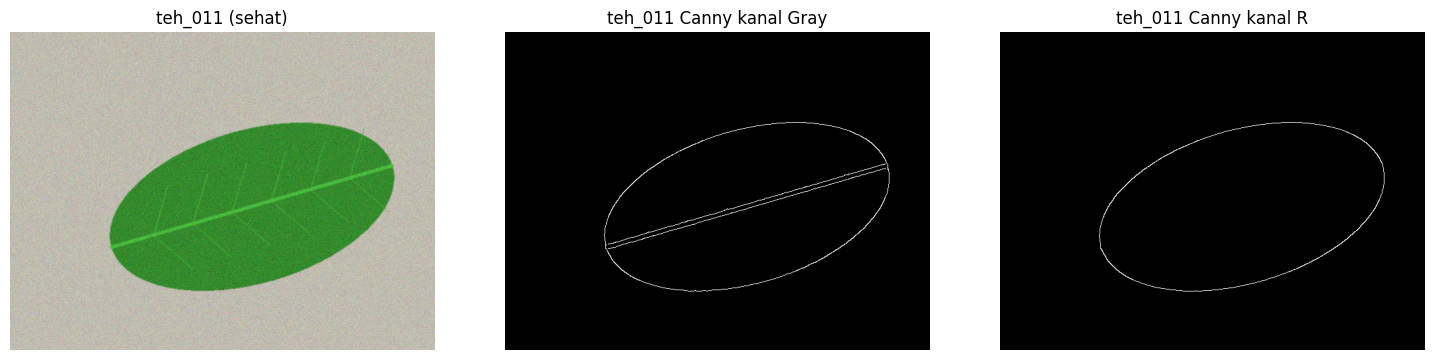

In [ ]:
baris, panel, judul = [], [], []
for _, d in label[label.kelas == "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    dalam = cv2.erode(md, np.ones((7, 7), np.uint8)) > 0   # bagian dalam daun
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        e = tepi_canny(g)
        baris.append([d.kondisi_cahaya, kanal, int(((e > 0) & dalam).sum())])
        if d.nama_file == "teh_011.png":
            panel.append(e); judul.append(f"teh_011 Canny kanal {kanal}")

sehat = pd.DataFrame(baris, columns=["kondisi", "kanal", "piksel_tepi_di_dalam_daun"])
print("=== RERATA PIKSEL TEPI PALSU DI DALAM DAUN SEHAT ===")
print(sehat.pivot_table(index="kondisi", columns="kanal", values="piksel_tepi_di_dalam_daun").round(1))
tampil([muat("teh_011.png")[0]] + panel, ["teh_011 (sehat)"] + judul, ukuran=(15, 3.6))